# Lecture 22 — Time series and spectral methods

We estimate the cycle period of the ten chemostat runs of Blasius et al., and the delay of the predator (rotifers) behind its prey (algae), with the discrete Fourier transform. The examples follow the sections of the notes.

[Lecture notes](https://teaching.borisbolliet.io/c1-2026/materials/class22/notes.pdf) · [Module at lecture-22-start](https://github.com/borisbolliet/attractor/blob/lecture-22-start/src/attractor/spectrum.py) · [Module at lecture-22](https://github.com/borisbolliet/attractor/blob/lecture-22/src/attractor/spectrum.py)

Run the cells in order with NumPy and Matplotlib installed. The functions of `spectrum.py` are included in the notebook, so a downloaded copy does not require an `attractor` installation. The data are read from `data/` of the clone. Timings are measured when the cells run.

In [1]:
%matplotlib inline
import math
import platform
import time
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

TAG = "lecture-22"
DATA = Path("data")
if not (DATA / "C1.csv").exists():   # outside a clone: download the ten runs at TAG
    DATA.mkdir(exist_ok=True)
    for i in range(1, 11):
        url = f"https://raw.githubusercontent.com/borisbolliet/attractor/{TAG}/data/C{i}.csv"
        urllib.request.urlretrieve(url, DATA / f"C{i}.csv")
print('Python', platform.python_version())
print('NumPy', np.__version__)

def seconds(function, *args, repeat=5):
    """Median elapsed time of function(*args), after one untimed call."""
    function(*args)
    durations = []
    for _ in range(repeat):
        start = time.perf_counter()
        function(*args)
        durations.append(time.perf_counter() - start)
    return float(np.median(durations))


def read(i):
    """Rows of run Ci with time, algae and rotifers all present."""
    d = np.genfromtxt(DATA / f"C{i}.csv", delimiter=",", skip_header=1, usecols=(0, 1, 2))
    return d[~np.isnan(d).any(axis=1)]

Python 3.13.11
NumPy 2.5.4


## 1. Sampled time series

### 1.1. Sampling interval and the Nyquist frequency

Samples taken at the times $t_n=t_0+n\,\Delta t$ are **uniformly sampled** with **sampling interval** $\Delta t$. The **sampling frequency** $f_s=1/\Delta t$ counts samples per unit of time. The **Nyquist frequency** $f_N=1/(2\Delta t)$ is the highest frequency that such samples represent.

A frequency above $f_N$ produces the same samples as a lower frequency: **aliasing**. A cycle of 0.8 days, 1.25 cycles per day, sampled once a day, gives the samples of a 4-day cycle, at $1.25-1=0.25$ cycles per day.

same samples: True


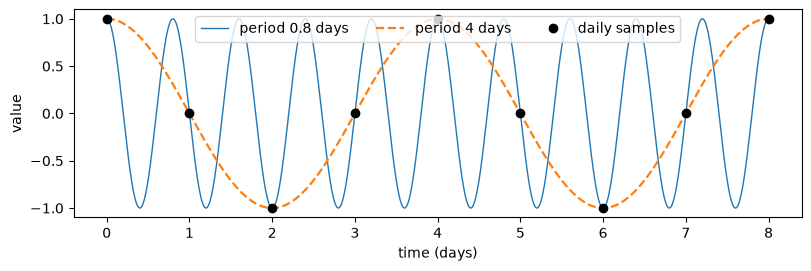

In [2]:
t = np.arange(12.0)                         # twelve daily samples
fast = np.cos(2 * np.pi * t / 0.8)          # 1.25 cycles per day
slow = np.cos(2 * np.pi * t / 4.0)          # 0.25 cycles per day
print('same samples:', np.allclose(fast, slow))

fine = np.linspace(0, 8, 2001)
fig, ax = plt.subplots(figsize=(8, 2.6), layout='constrained')
ax.plot(fine, np.cos(2 * np.pi * fine / 0.8), lw=1, label='period 0.8 days')
ax.plot(fine, np.cos(2 * np.pi * fine / 4.0), '--', lw=1.6, label='period 4 days')
ax.plot(t[:9], slow[:9], 'ko', label='daily samples')
ax.set(xlabel='time (days)', ylabel='value')
ax.legend(ncol=3, loc='upper center')
plt.show()

### 1.2. Checking the sampling of a record

The DFT treats sample $n$ as taken at time $n\,\Delta t$. Before any transform, we check the times of the samples and look for missing values. The first three columns of each file are the time in days, the algae density ($10^6$ cells per ml) and the rotifer density (animals per ml).

In [3]:
d = np.genfromtxt(DATA / "C1.csv", delimiter=",", skip_header=1, usecols=(0, 1, 2))
complete = ~np.isnan(d).any(axis=1)          # rows without a missing value
t = d[complete, 0]
dt = np.diff(t)                              # days between samples
print('rows:', len(d), ' complete:', int(complete.sum()))
print('intervals: min, median, max =', np.round([dt.min(), np.median(dt), dt.max()], 2))
print('intervals over 1.5 days:', int(np.sum(dt > 1.5)), ' longest from day', t[np.argmax(dt)])

print('run   rows  complete  median  longest')
for i in range(1, 11):
    raw = np.genfromtxt(DATA / f"C{i}.csv", delimiter=",", skip_header=1, usecols=(0, 1, 2))
    gaps = np.diff(read(i)[:, 0])
    print(f'C{i:<3} {len(raw):5d} {len(read(i)):9d} {np.median(gaps):7.2f} {gaps.max():8.2f}')

rows: 366  complete: 358
intervals: min, median, max = [0.57 1.01 5.03]
intervals over 1.5 days: 11  longest from day 341.98
run   rows  complete  median  longest
C1     366       358    1.01     5.03
C2     190       188    1.00     2.00
C3     182       180    1.00     2.18
C4     139       139    1.00     1.34
C5      86        74    1.00     3.02
C6     232       231    1.00     1.44
C7     235       234    1.00     1.41
C8     184       184    1.00     1.34
C9     141       141    1.01     1.31
C10    198       197    1.00     2.00


### 1.3. Resampling onto a uniform grid

**Linear interpolation** joins consecutive samples by straight lines and reads the lines at the new times. `np.interp` does not check that the sample times increase, so `uniform` checks them and raises `ValueError`.

In [4]:
def uniform(t, x, dt=1.0):
    """Interpolate samples linearly onto equally spaced times.

    Parameters
    ----------
    t : numpy.ndarray, shape (n,)
        Sample times, strictly increasing.
    x : numpy.ndarray, shape (n,)
        Sample values at the times t.
    dt : float, optional
        Spacing of the new times, in the units of t (default 1.0).

    Returns
    -------
    tu : numpy.ndarray
        The times t[0], t[0] + dt, t[0] + 2 dt, ..., up to t[-1].
    xu : numpy.ndarray
        x interpolated linearly at the times tu.

    Raises
    ------
    ValueError
        If t does not increase strictly; np.interp would then return
        meaningless values without raising an error.

    Examples
    --------
    >>> tu, xu = uniform([0.0, 0.9, 2.2, 3.1], [0.0, 1.8, 4.4, 6.2])
    >>> tu, xu
    (array([0., 1., 2., 3.]), array([0., 2., 4., 6.]))
    """
    t = np.asarray(t, dtype=float)
    if np.any(np.diff(t) <= 0):
        raise ValueError("sample times must increase strictly")
    m = int((t[-1] - t[0]) // dt) + 1
    tu = t[0] + dt * np.arange(m)
    return tu, np.interp(tu, t, x)


tu, algae_u = uniform(read(1)[:, 0], read(1)[:, 1])
print('first times:', tu[:3], ' values:', tu.size)
try:
    uniform([0.0, 2.0, 1.0], [5.0, 6.0, 7.0])
except ValueError as error:
    print('ValueError:', error)

first times: [0.95 1.95 2.95]  values: 374
ValueError: sample times must increase strictly


## 2. The discrete Fourier transform

### 2.1. Definition and frequencies

The **discrete Fourier transform** of $N$ samples is

$$X_k=\sum_{n=0}^{N-1}x_n\,e^{-2\pi i kn/N},\qquad k=0,1,\ldots,N-1.$$

Index $k$ counts $k$ cycles in the whole record: the frequency $f_k=k/(N\Delta t)$. Indices $k>N/2$ hold the negative frequencies $(k-N)/(N\Delta t)$, which `np.fft.fftfreq` lists last.

In [5]:
x = np.cos(2 * np.pi * 2 * np.arange(8) / 8)      # two cycles in eight samples
print('|X_k|:', np.abs(np.fft.fft(x)).round(12))
print('frequencies:', np.fft.fftfreq(8))

|X_k|: [0. 0. 4. 0. 0. 0. 4. 0.]
frequencies: [ 0.     0.125  0.25   0.375 -0.5   -0.375 -0.25  -0.125]


### 2.2. Real series and the real-input transform

For real samples, $X_{N-k}=\overline{X_k}$: **conjugate symmetry**. $X_0$ is real, and for even $N$ so is $X_{N/2}$. `np.fft.rfft` returns $X_0,\ldots,X_{N//2}$, `N // 2 + 1` values. A `float64` takes 8 bytes and a `complex128`, two `float64`, 16 bytes.

In [6]:
x = np.array([2.0, 0.0, 3.0, 0.0, 0.0, 1.0])
X = np.fft.fft(x)
print(X.round(3))
print('X[N-k] == conj(X[k]):', np.allclose(X[1:][::-1], X[1:].conj()))
print('rfft:', np.fft.rfft(x).round(3))

x = np.zeros(374)                                  # one value per day of C1
print('bytes: series', x.nbytes, ' fft', np.fft.fft(x).nbytes, ' rfft', np.fft.rfft(x).nbytes)

[6.+0.j    1.-1.732j 0.+3.464j 4.+0.j    0.-3.464j 1.+1.732j]
X[N-k] == conj(X[k]): True
rfft: [6.+0.j    1.-1.732j 0.+3.464j 4.+0.j   ]
bytes: series 2992  fft 5984  rfft 3008


### 2.3. Inverse transforms and their lengths

`irfft` and `hfft` take $m$ values of a half spectrum and return $2(m-1)$ real values unless `n` is given. For an odd length, the default result is one sample shorter, and its values differ from the series.

In [7]:
x = np.arange(13.0)
R = np.fft.rfft(x)
print('rfft values:', R.size)
print('irfft lengths:', np.fft.irfft(R).size, np.fft.irfft(R, n=13).size)
print('hfft lengths:', np.fft.hfft(R).size, np.fft.hfft(R, n=13).size)
print('irfft without n starts with', np.fft.irfft(R)[:2].round(3))
print('hfft(a, n) == n * irfft(conj(a), n):', np.allclose(np.fft.hfft(R, n=13), 13 * np.fft.irfft(R.conj(), n=13)))

rfft values: 7
irfft lengths: 12 13
hfft lengths: 12 13
irfft without n starts with [0.542 0.981]
hfft(a, n) == n * irfft(conj(a), n): True


### 2.4. The periodogram

The **periodogram** of $N$ real samples is $P_k=|X_k|^2$ for $k=0,\ldots,\lfloor N/2\rfloor$. Its frequencies are spaced by $1/T$, where $T=N\Delta t$ is the duration of the record. `fourier` removes the mean, applies a Hann window if asked (Section 4.3) and calls `rfft` along one axis.

In [8]:
def fourier(x, dt=1.0, n=None, window=True, axis=-1):
    """Frequencies and Fourier coefficients of real samples taken every dt.

    The mean of each series is removed first. With window=True the samples
    are multiplied by a Hann window, which reduces leakage between
    frequencies. An n larger than the number of samples m pads them with
    zeros: the frequencies are then k / (n dt), a finer grid.

    Returns
    -------
    f : numpy.ndarray, shape (n // 2 + 1,)
        Frequencies in cycles per unit of t, from 0 to the Nyquist frequency.
    X : numpy.ndarray of complex
        The coefficients of numpy.fft.rfft, with n // 2 + 1 values along axis.
    """
    x = np.moveaxis(np.asarray(x, dtype=float), axis, -1)
    m = x.shape[-1]
    n = m if n is None else n
    x = x - x.mean(axis=-1, keepdims=True)
    if window:
        x = x * np.hanning(m)  # shape (m,), broadcast over the leading axes
    X = np.fft.rfft(x, n=n)
    return np.fft.rfftfreq(n, d=dt), np.moveaxis(X, -1, axis)


def periodogram(x, dt=1.0, n=None, window=True, axis=-1):
    """Frequencies and power |X_k|**2 of real samples; arguments as for `fourier`.

    Examples
    --------
    >>> x = np.cos(2 * np.pi * np.arange(16) / 4)     # period of 4 samples
    >>> f, power = periodogram(x, window=False)
    >>> float(f[np.argmax(power)])
    0.25
    """
    f, X = fourier(x, dt, n, window, axis)
    return f, np.abs(X) ** 2


def dominant_period(f, power, shortest, longest, axis=-1):
    """Period 1 / f of the largest power among periods from shortest to longest.

    Examples
    --------
    >>> f = np.array([0.0, 0.1, 0.2, 0.3])
    >>> float(dominant_period(f, np.array([9.0, 1.0, 3.0, 2.0]), 3, 20))
    5.0
    """
    power = np.moveaxis(power, axis, -1)
    band = (f >= 1 / longest) & (f <= 1 / shortest)
    return 1 / f[np.argmax(np.where(band, power, -np.inf), axis=-1)]

grid spacing: 0.0070921985815602835  periods for k = 17, 18, 19: [8.29 7.83 7.42]
dominant period on the grid: 7.833333333333334


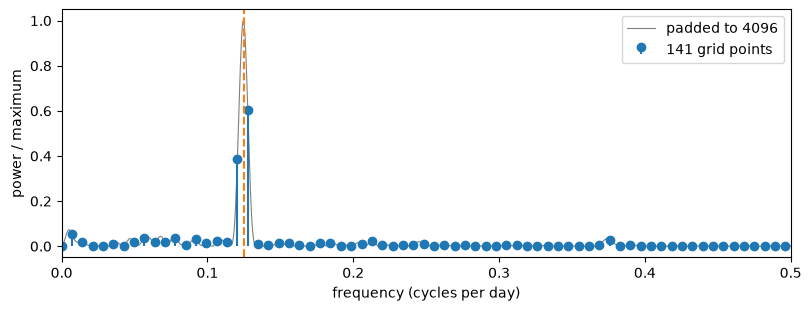

C1 algae, samples taken as daily: 6.79
C1 algae, resampled: 6.99


In [9]:
t9, algae9 = uniform(read(9)[:, 0], read(9)[:, 1])
f, p = periodogram(algae9, window=False)
print('grid spacing:', f[1], ' periods for k = 17, 18, 19:', (1 / f[17:20]).round(2))
print('dominant period on the grid:', dominant_period(f, p, 3, 20))
fp, pp = periodogram(algae9, n=4096, window=False)

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.plot(fp, pp / pp.max(), color='grey', lw=0.8, label='padded to 4096')
ax.stem(f, p / pp.max(), basefmt=' ', label='141 grid points')
ax.axvline(1 / 8, ls='--', color='C1')
ax.set(xlabel='frequency (cycles per day)', ylabel='power / maximum', xlim=(0, 0.5))
ax.legend()
plt.show()

d1 = read(1)
tu1, au1 = uniform(d1[:, 0], d1[:, 1])
print('C1 algae, samples taken as daily:', round(float(dominant_period(*periodogram(d1[:, 1], n=4096), 3, 20)), 2))
print('C1 algae, resampled:', round(float(dominant_period(*periodogram(au1, n=4096), 3, 20)), 2))

## 3. The fast Fourier transform

### 3.1. The DFT as a matrix–vector product

$\boldsymbol X=W\boldsymbol x$ with $W_{kn}=e^{-2\pi ikn/N}$: $N^2$ complex entries of 16 bytes and $\Theta(N^2)$ operations.

In [10]:
N = 8
k = np.arange(N)
W = np.exp(-2j * np.pi * np.outer(k, k) / N)
x = np.random.default_rng(0).standard_normal(N)
print('W @ x == fft(x):', np.allclose(W @ x, np.fft.fft(x)), ' W bytes:', W.nbytes)
print('MiB of W for N = 4096:', 4096 ** 2 * 16 / 2 ** 20)

W @ x == fft(x): True  W bytes: 1024
MiB of W for N = 4096: 256.0


### 3.2. Splitting into even and odd samples

$X_k=E_k+e^{-2\pi ik/N}O_k$ and $X_{k+N/2}=E_k-e^{-2\pi ik/N}O_k$, where $E$ and $O$ are the DFTs of length $N/2$ of the even and odd samples. Splitting again, down to length 1, gives the recursion $T(N)=2T(N/2)+\Theta(N)$, hence $\Theta(N\log N)$. A recursive version for $N$ a power of two:

In [11]:
def fft_recursive(x):
    """DFT of x, len(x) a power of two, by splitting into even and odd samples."""
    N = len(x)
    if N == 1:
        return np.asarray(x, dtype=complex)
    E, O = fft_recursive(x[0::2]), fft_recursive(x[1::2])
    w = np.exp(-2j * np.pi * np.arange(N // 2) / N)
    return np.concatenate([E + w * O, E - w * O])


x = np.random.default_rng(1).standard_normal(16)
print('recursive == np.fft.fft:', np.allclose(fft_recursive(x), np.fft.fft(x)))

recursive == np.fft.fft: True


### 3.3. Measured cost and padded sizes

Median times of a matrix–vector product with a precomputed $W$ and of `np.fft.fft`, then FFT lengths with and without a large prime factor. A common remedy for an awkward length is to pad with zeros to $N=2^{\lceil\log_2 n\rceil}$.

In [12]:
rng = np.random.default_rng(0)
print('     N   matrix (ms)   fft (ms)   ratio   N/log2 N')
for N in (512, 1024, 2048, 4096):
    k = np.arange(N)
    W = np.exp(-2j * np.pi * np.outer(k, k) / N)
    x = rng.standard_normal(N)
    t_matrix, t_fft = seconds(W.__matmul__, x), seconds(np.fft.fft, x)
    print(f'{N:6d} {1e3 * t_matrix:12.3f} {1e3 * t_fft:10.4f} {t_matrix / t_fft:7.0f} {N / math.log2(N):9.0f}')
del W
for N, factors in ((2**20, '2**20'), (2**20 - 3, 'prime')):
    x = rng.standard_normal(N)
    print(f'{N:9d} {factors:6s} fft: {1e3 * seconds(np.fft.fft, x):6.2f} ms')
print('374 days padded to', 2 ** math.ceil(math.log2(374)))

     N   matrix (ms)   fft (ms)   ratio   N/log2 N
   512        0.022     0.0040       6        57
  1024        0.211     0.0099      21       102
  2048        0.529     0.0111      48       186


  4096        2.386     0.0207     115       341
  1048576 2**20  fft:  11.08 ms


  1048573 prime  fft:  75.44 ms
374 days padded to 512


### 3.4. Transforms along an axis

Each function moves the axis of time last with `np.moveaxis`, then works with `axis=-1` and `...`. The Hann window of shape `(m,)` broadcasts over the leading axes.

In [13]:
d9 = read(9)
D = np.column_stack([uniform(d9[:, 0], d9[:, j])[1] for j in (1, 2)])
x = np.moveaxis(D, 0, -1)
print('D', D.shape, '-> moveaxis', x.shape, '-> mean keepdims', x.mean(axis=-1, keepdims=True).shape,
      '-> window', np.hanning(141).shape, '-> rfft', np.fft.rfft(x, n=4096).shape)
f, power = periodogram(D, n=4096, axis=0)
print('periodogram along axis 0:', f.shape, power.shape)

D (141, 2) -> moveaxis (2, 141) -> mean keepdims (2, 1) -> window (141,) -> rfft (2, 2049)
periodogram along axis 0: (2049,) (2049, 2)


## 4. Spectral leakage and windows

### 4.1. Zero padding and the frequency grid

Padding $N$ samples with zeros to $n$ evaluates the same sum at the finer grid $k/(n\Delta t)$. It interpolates the periodogram; it does not separate two cycles closer than about $1/T$.

### 4.2. Leakage

**Spectral leakage** is the appearance of power at frequencies other than those of the oscillations in the signal. The DFT treats the record as one period of a periodic series, which jumps where $x_{N-1}$ meets $x_0$ when the record holds a non-integer number of cycles.

### 4.3. The Hann window

The **Hann window** $w_n=\sin^2(\pi n/(N-1))$ brings both ends of the record to zero.

Hann window of 5: [0.  0.5 1.  0.5 0. ]
grid: 7.833333333333334  padded: 8.0
power at 0.25 per day: 4.0e-04 without window, 3.7e-09 with Hann
C9 algae, Hann and padding: 8.016


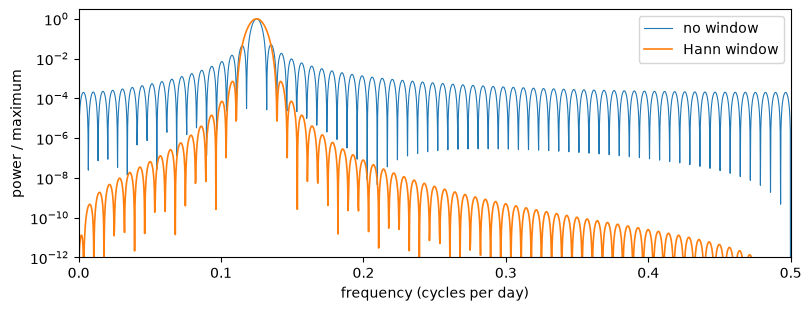

In [14]:
print('Hann window of 5:', np.hanning(5))
x = np.cos(2 * np.pi * np.arange(141) / 8.0)      # 17.625 cycles in the record
print('grid:', dominant_period(*periodogram(x, window=False), 3, 20),
      ' padded:', dominant_period(*periodogram(x, n=4096, window=False), 3, 20))
f, p = periodogram(x, n=4096, window=False)
f, q = periodogram(x, n=4096)
k = np.searchsorted(f, 0.25)
print(f'power at 0.25 per day: {p[k] / p.max():.1e} without window, {q[k] / q.max():.1e} with Hann')
print('C9 algae, Hann and padding:', round(float(dominant_period(*periodogram(algae9, n=4096), 3, 20)), 3))

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.semilogy(f, p / p.max(), lw=0.8, label='no window')
ax.semilogy(f, q / q.max(), lw=1.2, label='Hann window')
ax.set(xlabel='frequency (cycles per day)', ylabel='power / maximum', ylim=(1e-12, 3), xlim=(0, 0.5))
ax.legend()
plt.show()

### 4.4. Periods of the ten runs

For each run: resample both densities, compute their periodograms with a Hann window and padding to 4096, and take the dominant period between 3 and 20 days. The last column is the mean spacing of the algae peaks of L4, with the data read as L4 read them (`float32`, rows with an algae value).

In [15]:
def peaks(t, x, min_gap=3.0):
    """Return indices of peaks above the mean, separated by at least min_gap.

    Parameters
    ----------
    t : numpy.ndarray, shape (n,)
        Sample times in increasing order.
    x : numpy.ndarray, shape (n,)
        Finite sample values corresponding to t.
    min_gap : float, optional
        Minimum time between retained peaks, in the units of t (default 3.0).

    Returns
    -------
    numpy.ndarray of int
        Indices of the retained peaks, in time order. The array is empty
        when no peaks are found.

    Notes
    -----
    An interior sample is a candidate when it is above the mean of x,
    strictly above its left neighbour, and at least as high as its right
    neighbour. If it is too close to the last retained peak, keep the
    higher of the two; an equal height leaves the earlier peak in place.
    The first and last samples are not candidates.
    """
    level = x.mean()
    found = []
    for i in range(1, len(x) - 1):
        if not (x[i - 1] < x[i] >= x[i + 1] and x[i] > level):
            continue
        if found and t[i] - t[found[-1]] < min_gap:
            if x[i] > x[found[-1]]:
                found[-1] = i  # the higher of two close maxima is kept
            continue
        found.append(i)
    return np.array(found, dtype=int)


def cycle_period(t, x, min_gap=3.0):
    """Estimate a period from the mean spacing of retained peaks.

    Parameters
    ----------
    t : numpy.ndarray, shape (n,)
        Sample times in increasing order.
    x : numpy.ndarray, shape (n,)
        Finite sample values corresponding to t.
    min_gap : float, optional
        Minimum separation of retained peaks, in the units of t (default 3.0).

    Returns
    -------
    period : float
        Mean spacing between consecutive retained peaks, in the units of t.
        Returns numpy.nan when fewer than three peaks are found.
    peak_times : numpy.ndarray
        Times of all retained peaks, including when period is NaN.

    See Also
    --------
    peaks : Peak selection and treatment of nearby maxima.
    """
    p = peaks(t, x, min_gap)
    if len(p) < 3:
        return np.nan, t[p]
    return (t[p[-1]] - t[p[0]]) / (len(p) - 1), t[p]

run   algae  rotifers  L4 peaks
C1     6.99      7.05      6.60
C2     7.11      7.00      4.97
C3     4.45      7.10      5.61
C4     6.65      6.65      7.16
C5     7.17     10.56      6.67
C6     7.79      8.73      9.25
C7     7.11      7.06      7.00
C8     8.05      8.06      8.05
C9     8.02      8.06      8.06
C10    7.01      7.34      6.63


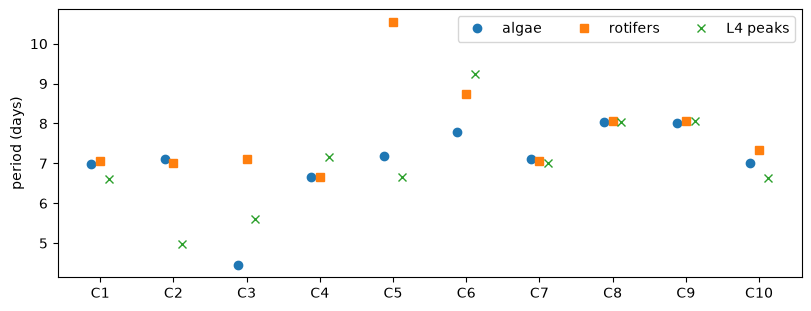

In [16]:
periods = []
print('run   algae  rotifers  L4 peaks')
for i in range(1, 11):
    d = read(i)
    D = np.column_stack([uniform(d[:, 0], d[:, j])[1] for j in (1, 2)])
    f, P = periodogram(D, n=4096, axis=0)
    algae, rotifers = dominant_period(f, P, 3, 20, axis=0)
    raw = np.genfromtxt(DATA / f"C{i}.csv", delimiter=",", skip_header=1, dtype=np.float32)
    keep = ~np.isnan(raw[:, 1])
    l4 = cycle_period(raw[keep, 0], raw[keep, 1])[0]
    periods.append((algae, rotifers, l4))
    print(f'C{i:<3} {algae:6.2f} {rotifers:9.2f} {l4:9.2f}')

periods = np.array(periods)
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
runs = np.arange(1, 11)
for col, marker, label in ((0, 'o', 'algae'), (1, 's', 'rotifers'), (2, 'x', 'L4 peaks')):
    ax.plot(runs + 0.12 * (col - 1), periods[:, col], marker, label=label)
ax.set(xticks=runs, xticklabels=[f'C{i}' for i in runs], ylabel='period (days)')
ax.legend(ncol=3)
plt.show()

## 5. Convolution and filtering

### 5.1. Convolution and the convolution theorem

The **convolution** of $x_0,\ldots,x_{n-1}$ with a kernel $k_0,\ldots,k_{w-1}$ has $n+w-1$ values $(x*k)_m=\sum_j k_jx_{m-j}$. A **moving average** over $w$ samples uses $k_j=1/w$. The **circular convolution** of two series of length $N$ takes indices modulo $N$. **Convolution theorem**: the DFT of a circular convolution is the product of the DFTs.

In [17]:
rng = np.random.default_rng(2)
a, b = rng.standard_normal(8), rng.standard_normal(8)
direct = np.array([sum(b[j] * a[(m - j) % 8] for j in range(8)) for m in range(8)])
by_fft = np.fft.irfft(np.fft.rfft(a) * np.fft.rfft(b), 8)
print('circular convolution == irfft(rfft(a) * rfft(b)):', np.allclose(direct, by_fft))

circular convolution == irfft(rfft(a) * rfft(b)): True


### 5.2. Wrap-around and zero padding

With transforms of length $n$, the last $w-1$ sums of the convolution wrap around onto the first ones. Padding to $N\geq n+w-1$ leaves room for all of them. At `lecture-22-start`, `moving_average` multiplies transforms of length $n$:

In [18]:
x = np.array([3.0, 6.0, 9.0, 12.0])
k = np.ones(3) / 3
print('np.convolve (6 sums):', np.convolve(x, k))
print('length 4:', np.fft.irfft(np.fft.rfft(x) * np.fft.rfft(k, 4), 4))
print('padded to 8:', np.fft.irfft(np.fft.rfft(x, 8) * np.fft.rfft(k, 8), 8))

np.convolve (6 sums): [1. 3. 6. 9. 7. 4.]
length 4: [8. 7. 6. 9.]
padded to 8: [1. 3. 6. 9. 7. 4. 0. 0.]


In [19]:
def moving_average_circular(x, w, axis=-1):
    """Centred moving average over w samples, computed as a product of FFTs.

    Examples
    --------
    >>> moving_average(np.array([3.0, 6.0, 9.0, 12.0]), 3)
    array([7., 6., 9., 8.])
    """
    x = np.moveaxis(np.asarray(x, dtype=float), axis, -1)
    n = x.shape[-1]
    kernel = np.fft.rfft(np.ones(w) / w, n)
    y = np.fft.irfft(np.fft.rfft(x) * kernel, n)
    lo = (w - 1) // 2  # w // 2 samples before the centre, (w - 1) // 2 after
    return np.moveaxis(np.roll(y, -lo, axis=-1), -1, axis)


def moving_average(x, w, axis=-1):
    """Centred moving average over w samples, computed as a product of FFTs.

    The result equals np.convolve(x, np.ones(w) / w, mode="same") along
    axis: values beyond the two ends of the record count as zero. The
    transforms have length N >= n + w - 1, so that the end of the series does
    not wrap around onto its start.

    Examples
    --------
    >>> moving_average(np.array([3.0, 6.0, 9.0, 12.0]), 3)
    array([3., 6., 9., 7.])
    """
    x = np.moveaxis(np.asarray(x, dtype=float), axis, -1)
    n = x.shape[-1]
    N = 2 ** math.ceil(math.log2(n + w - 1))  # room for all n + w - 1 sums
    kernel = np.fft.rfft(np.ones(w) / w, N)
    y = np.fft.irfft(np.fft.rfft(x, N) * kernel, N)
    lo = (w - 1) // 2  # w // 2 samples before the centre, (w - 1) // 2 after
    return np.moveaxis(y[..., lo:lo + n], -1, axis)

first samples: [3.41 2.45 3.71 8.19]  last samples: [24.89 39.78 40.3 ]
circular, first averages: [17.53 15.93 16.7 ]
padded, first averages:   [ 2.54  4.49 10.95]
N for n = 230, w = 7: 256
w = 3: largest difference from np.convolve, circular 0.68, padded 3.3e-16
w = 4: largest difference from np.convolve, circular 0.39, padded 2.2e-16
w = 7: largest difference from np.convolve, circular 0.29, padded 2.2e-16
w = 8: largest difference from np.convolve, circular 0.55, padded 3.3e-16


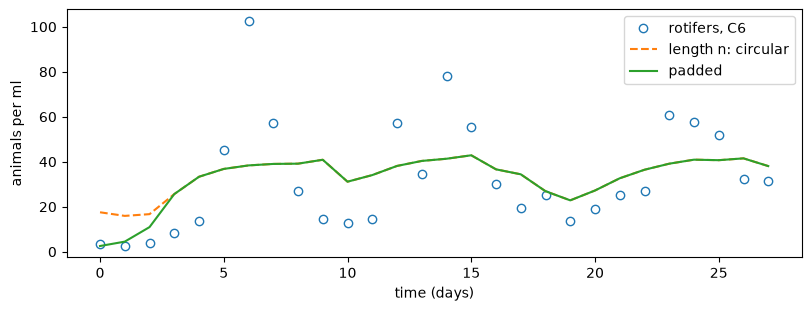

In [20]:
d6 = read(6)
t6, rot6 = uniform(d6[:, 0], d6[:, 2])
print('first samples:', rot6[:4].round(2), ' last samples:', rot6[-3:].round(2))
print('circular, first averages:', moving_average_circular(rot6, 7)[:3].round(2))
print('padded, first averages:  ', moving_average(rot6, 7)[:3].round(2))
print('N for n = 230, w = 7:', 2 ** math.ceil(math.log2(230 + 7 - 1)))
for w in (3, 4, 7, 8):
    x = np.random.default_rng(w).standard_normal(50)
    expected = np.convolve(x, np.ones(w) / w, "same")
    print(f'w = {w}: largest difference from np.convolve, circular '
          f'{np.abs(moving_average_circular(x, w) - expected).max():.2f}, padded '
          f'{np.abs(moving_average(x, w) - expected).max():.1e}')

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
days = t6 < 28
ax.plot(t6[days], rot6[days], 'o', mfc='none', label='rotifers, C6')
ax.plot(t6[days], moving_average_circular(rot6, 7)[days], '--', label='length n: circular')
ax.plot(t6[days], moving_average(rot6, 7)[days], label='padded')
ax.set(xlabel='time (days)', ylabel='animals per ml')
ax.legend()
plt.show()

### 5.3. The centre of an even window

The slice start `lo = (w - 1) // 2` puts `w // 2` samples before the centre and `(w - 1) // 2` after, as `np.convolve(x, k, "same")` does. The two expressions agree for odd $w$ only, so a test needs windows of both parities.

In [21]:
print([(w, (w - 1) // 2, w // 2) for w in range(3, 9)])

[(3, 1, 1), (4, 1, 2), (5, 2, 2), (6, 2, 3), (7, 3, 3), (8, 3, 4)]


### 5.4. Cost of a long convolution

A correlation of two records of $n$ samples has $2n-1$ lags, so the transforms need $N\geq2n-1$. Count $n^2$ operations for the direct sums and $N\log_2N$ for one FFT.

In [22]:
n = 525_600                                       # one sample a minute for a year
N = 2 ** math.ceil(math.log2(2 * n - 1))
print('N =', N, ' dense n x n float64 matrix:', round(n * n * 8 / 2 ** 30), 'GiB')
print(f'counts: {n * n:.2e} direct, {N * math.log2(N):.2e} one FFT, ratio {n * n / (N * math.log2(N)):.0f}')

N = 2097152  dense n x n float64 matrix: 2058 GiB
counts: 2.76e+11 direct, 4.40e+07 one FFT, ratio 6273


### 5.5. Frequency response of a moving average

$|H(f)|=|\sin(\pi fw\Delta t)/(w\sin(\pi f\Delta t))|$ vanishes at $f=j/(w\Delta t)$: a moving average over $w$ samples removes a cycle of $w$ samples.

w = 3: |H(1/8)| = 0.805
w = 8: |H(1/8)| = 0.000


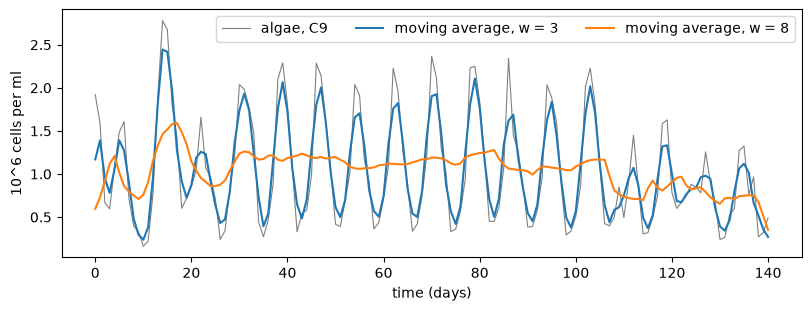

In [23]:
for w in (3, 8):
    H = abs(np.sin(np.pi * w / 8) / (w * np.sin(np.pi / 8)))
    print(f'w = {w}: |H(1/8)| = {H:.3f}')

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.plot(t9, algae9, color='grey', lw=0.8, label='algae, C9')
for w in (3, 8):
    ax.plot(t9, moving_average(algae9, w), lw=1.5, label=f'moving average, w = {w}')
ax.set(xlabel='time (days)', ylabel='10^6 cells per ml')
ax.legend(ncol=3)
plt.show()

### 5.6. Ringing of a sharp cut-off

Setting every $X_k$ above a cut-off to zero is a convolution with an oscillating kernel. Near a jump, the result overshoots: the **Gibbs phenomenon**. The overshoot stays near 9% of the jump however many frequencies are kept.

In [24]:
for size, K in ((400, 30), (4000, 300)):
    x = (np.arange(size) % (size // 2) < size // 4).astype(float)
    X = np.fft.rfft(x)
    X[K + 1:] = 0
    y = np.fft.irfft(X, n=size)
    print(f'{size} samples, k <= {K}: max {y.max():.3f}, min {y.min():.3f}')
z = np.convolve((np.arange(400) % 200 < 100).astype(float), np.ones(15) / 15, mode="same")
print('moving average: max', z.max().round(3), ' min', z.min().round(3))

400 samples, k <= 30: max 1.090, min -0.090
4000 samples, k <= 300: max 1.090, min -0.090
moving average: max 1.0  min 0.0


## 6. Cross-correlation and phase lag

### 6.1. Cross-correlation

For standardised series, $c(\tau)=\frac1n\sum_m\tilde x_m\,\tilde y_{m+\tau}$. A maximum at $\tau>0$ means that $y$ follows $x$ by $\tau$ samples. Its transform is $\overline{\tilde X_j}\,\tilde Y_j$, and the $2n-1$ lags need $N\geq 2n-1$.

In [25]:
def cross_correlation(x, y, axis=-1):
    """Correlation of y against x at every lag, computed by FFT.

    Both series are standardised (mean removed, divided by the standard
    deviation). Then c[tau] is the sum of x[k] * y[k + tau] over the pairs
    inside the record, divided by n. A maximum at tau > 0 means that y
    follows x by tau samples.

    Returns
    -------
    lags : numpy.ndarray of int, shape (2 n - 1,)
        The lags -(n - 1), ..., n - 1.
    c : numpy.ndarray
        The correlation at each lag, along axis.

    Examples
    --------
    >>> lags, c = cross_correlation([1.0, 2.0, 0.0, 0.0], [0.0, 1.0, 2.0, 0.0])
    >>> int(lags[np.argmax(c)])
    1
    """
    x = np.moveaxis(np.asarray(x, dtype=float), axis, -1)
    y = np.moveaxis(np.asarray(y, dtype=float), axis, -1)
    n = x.shape[-1]
    xs = (x - x.mean(axis=-1, keepdims=True)) / x.std(axis=-1, keepdims=True)
    ys = (y - y.mean(axis=-1, keepdims=True)) / y.std(axis=-1, keepdims=True)
    N = 2 ** math.ceil(math.log2(2 * n - 1))  # room for all 2n - 1 lags
    c = np.fft.irfft(np.fft.rfft(xs, N).conj() * np.fft.rfft(ys, N), N) / n
    # the circular result holds lags 0 .. n - 1, then the negative lags
    c = np.concatenate([c[..., N - n + 1:], c[..., :n]], axis=-1)
    return np.arange(-(n - 1), n), np.moveaxis(c, -1, axis)

In [26]:
t = np.arange(60.0)
prey = np.cos(2 * np.pi * t / 7)
predator = np.cos(2 * np.pi * (t - 2) / 7)        # the same cycle, 2 days later
lags, c = cross_correlation(prey, predator)
print('lags:', lags.size, ' largest correlation at lag', lags[np.argmax(c)], ' phase', round(360 * 2 / 7, 1))
x, y = np.random.default_rng(7).standard_normal((2, 30))
xs, ys = (x - x.mean()) / x.std(), (y - y.mean()) / y.std()
print('matches np.correlate:', np.allclose(cross_correlation(x, y)[1], np.correlate(ys, xs, "full") / 30))

lags: 119  largest correlation at lag 2  phase 102.9
matches np.correlate: True


### 6.2. Phase lag

For two oscillations with a common period $P$, a delay $\tau$ is the **phase lag** $\theta=360^\circ\,\tau/P$. With daily samples the lag moves in steps of $360^\circ/P$. The **cross-spectrum** $S=X\,\overline{Y}$ has the argument $2\pi f\tau\Delta t$, without that step.

In [27]:
d1 = read(1)
D1 = np.column_stack([uniform(d1[:, 0], d1[:, j])[1] for j in (1, 2)])
lags, c = cross_correlation(D1[:, 0], D1[:, 1])
print('C1, correlation at lags 1, 2, 3 days:', c[(lags >= 1) & (lags <= 3)].round(2))
f, X = fourier(D1, n=4096, axis=0)
S = X[:, 0] * X[:, 1].conj()
k = np.argmax(np.abs(S) * ((f >= 1 / 20) & (f <= 1 / 3)))
theta = np.degrees(np.angle(S[k]))
print(f'cross-spectrum: period {1 / f[k]:.2f} days, phase {theta:.1f} degrees, delay {theta / 360 / f[k]:.2f} days')

C1, correlation at lags 1, 2, 3 days: [ 0.4   0.29 -0.03]
cross-spectrum: period 7.01 days, phase 87.2 degrees, delay 1.70 days


### 6.3. Phase lags of the ten runs

For each run: the period of the largest cross-spectrum between 3 and 20 days, the phase there, and the lag of the largest correlation between 0 and that period. Blasius et al. report $93^\circ\pm21^\circ$ for C1 to C5, averaged over the intervals of coherent oscillation.

In [28]:
phases = []
print('run   period  lag  phase(lag)  phase(cross-spectrum)')
for i in range(1, 11):
    d = read(i)
    D = np.column_stack([uniform(d[:, 0], d[:, j])[1] for j in (1, 2)])
    f, X = fourier(D, n=4096, axis=0)
    S = X[:, 0] * X[:, 1].conj()
    period = float(dominant_period(f, np.abs(S), 3, 20))
    k = np.argmin(np.abs(f - 1 / period))
    theta = float(np.degrees(np.angle(S[k])) % 360)
    lags, c = cross_correlation(D[:, 0], D[:, 1])
    sel = (lags >= 0) & (lags < period)
    lag = int(lags[sel][np.argmax(c[sel])])
    phases.append(theta)
    print(f'C{i:<3} {period:7.2f} {lag:4d} {360 * lag / period:10.0f} {theta:14.0f}')
phases = np.array(phases)
print(f'C1 to C5: mean {phases[:5].mean():.0f} degrees, standard deviation {phases[:5].std(ddof=1):.0f}')

run   period  lag  phase(lag)  phase(cross-spectrum)
C1      7.01    1         51             87
C2      7.05    1         51             28
C3      7.06    1         51            107
C4      6.65    2        108             87
C5     10.67    2         68             73
C6      8.71    2         83            100
C7      7.07    3        153             91
C8      8.05    2         89             50
C9      8.05    2         89             73
C10     7.10    1         51             57
C1 to C5: mean 77 degrees, standard deviation 29


The notes contain exercises with worked solutions on half spectra, padded sizes and operation counts, shapes through a moving average along an axis, aliasing, and phase lags.